In [1]:
#q1
import numpy as np
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

matrix = np.random.rand(3, 3)
kernel = np.random.rand(3, 3)

print("Original Matrix:\n", matrix)
print("\nKernel:\n", kernel)

padded = np.pad(matrix, ((1, 1), (1, 1)), mode="constant")
output = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        output[i, j] = np.sum(padded[i:i+3, j:j+3] * kernel)

print("\nConvolution with Padding P=1:\n", output)

relu = np.maximum(0, output)
sigmoid = 1 / (1 + np.exp(-output))

print("\nReLU:\n", relu)
print("\nSigmoid:\n", sigmoid)

max_pool = np.max(relu[:2, :2])
min_pool = np.min(relu[:2, :2])
global_avg_pool = np.mean(relu)

print("\nMax Pooling:", max_pool)
print("Min Pooling:", min_pool)
print("Global Average Pooling:", global_avg_pool)

flattened = relu.flatten()
print("\nFlattened Output:\n", flattened)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(9,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.summary()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early Stopping Callback Created Successfully")


Original Matrix:
 [[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]
 [0.05808361 0.86617615 0.60111501]]

Kernel:
 [[0.70807258 0.02058449 0.96990985]
 [0.83244264 0.21233911 0.18182497]
 [0.18340451 0.30424224 0.52475643]]

Convolution with Padding P=1:
 [[0.5164021  0.88587503 1.02292072]
 [1.55750658 2.14420024 1.19298795]
 [0.33347297 0.91997791 0.96236577]]

ReLU:
 [[0.5164021  0.88587503 1.02292072]
 [1.55750658 2.14420024 1.19298795]
 [0.33347297 0.91997791 0.96236577]]

Sigmoid:
 [[0.62630607 0.70803819 0.73554113]
 [0.82599527 0.89512557 0.76727503]
 [0.58260416 0.7150376  0.72359522]]

Max Pooling: 2.14420024234303
Min Pooling: 0.5164020983612387
Global Average Pooling: 1.0595232516429673

Flattened Output:
 [0.5164021  0.88587503 1.02292072 1.55750658 2.14420024 1.19298795
 0.33347297 0.91997791 0.96236577]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 275 (1.07 KB)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 32 (128.00 B)

Early Stopping Callback Created Successfully


Selected Classes: ['n01443537', 'n01629819', 'n01641577']
Dataset Shape: (600, 64, 64, 3)
Total Images: 600
Training Images: 420
Validation Images: 90
Testing Images: 90


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,555 (435.76 KB)

 Trainable params: 110,851 (433.01 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 343ms/step - accuracy: 0.5762 - loss: 1.0890 - val_accuracy: 0.3333 - val_loss: 1.0909
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 316ms/step - accuracy: 0.6595 - loss: 0.8673 - val_accuracy: 0.4556 - val_loss: 1.1040
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 391ms/step - accuracy: 0.7071 - loss: 0.7198 - val_accuracy: 0.5000 - val_loss: 1.0870
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 328ms/step - accuracy: 0.7381 - loss: 0.6828 - val_accuracy: 0.4444 - val_loss: 1.1010
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 417ms/step - accuracy: 0.7214 - loss: 0.6748 - val_accuracy: 0.3333 - val_loss: 1.1234
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 315ms/step - accuracy: 0.7762 - loss: 0.5862 - val_accuracy: 0.6000 - val_loss: 1.1285
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 494ms/step - accuracy: 0.7929 - loss: 0.5553 - val_accuracy: 0.5556 - val_loss: 1.1594


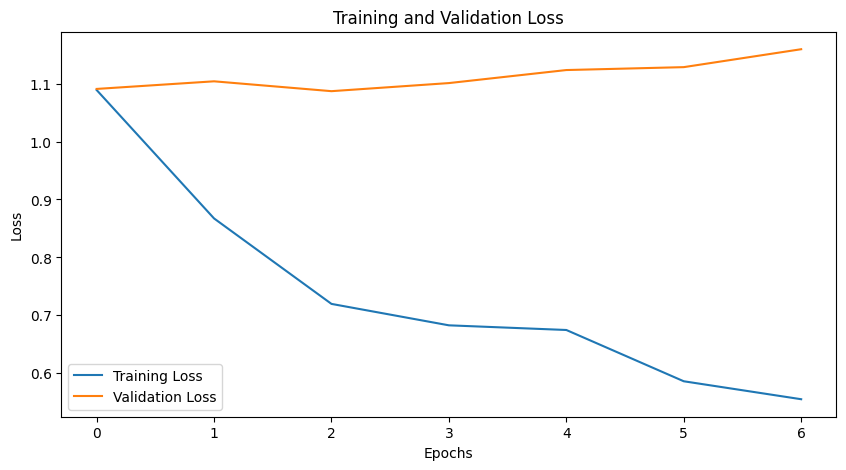

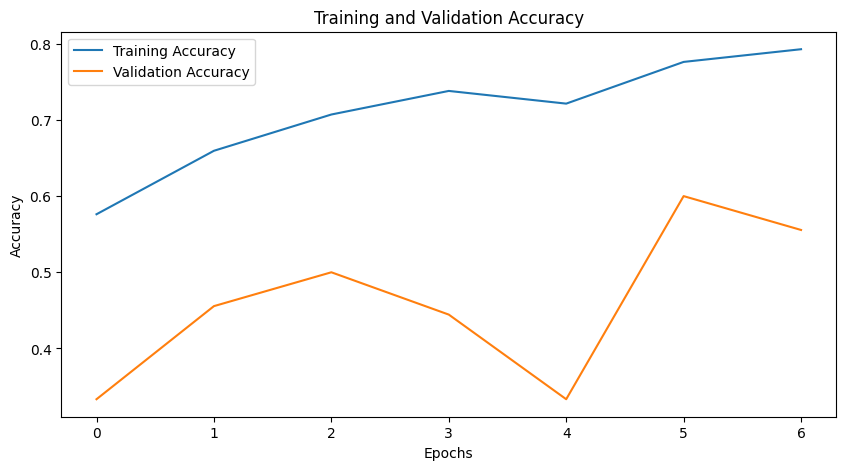

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step

 Custom CNN
Accuracy: 0.4667
Precision: 0.4024
Recall: 0.4667
F1 Score: 0.3798


In [2]:

import os
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras import layers, models

# Q2

url = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
zip_path = "/content/tiny-imagenet-200.zip"
data_path = "/content/tiny-imagenet-200"

if not os.path.exists(data_path):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content")

train_path = os.path.join(data_path, "train")

classes = sorted([
    d for d in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, d))
])[:3]

X = []
y = []

for label, class_name in enumerate(classes):
    image_folder = os.path.join(train_path, class_name, "images")
    image_files = sorted(os.listdir(image_folder))[:200]

    for file in image_files:
        image_path = os.path.join(image_folder, file)
        image = tf.keras.utils.load_img(
            image_path, target_size=(64, 64)
        )
        image = tf.keras.utils.img_to_array(image)

        X.append(image)
        y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Selected Classes:", classes)
print("Dataset Shape:", X.shape)
print("Total Images:", len(X))

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

def build_custom_cnn():

    model = models.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Rescaling(1./255),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

custom_model = build_custom_cnn()
custom_model.summary()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = custom_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping]
)

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

def calculate_metrics(y_true, y_pred, model_name):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    print("\n", model_name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    return [accuracy, precision, recall, f1]

custom_predictions = np.argmax(
    custom_model.predict(X_test), axis=1
)

custom_metrics = calculate_metrics(
    y_test, custom_predictions, "Custom CNN"
)



Training: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.5119 - loss: 9.1461 - val_accuracy: 0.8111 - val_loss: 1.3256
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7786 - loss: 2.3832 - val_accuracy: 0.8667 - val_loss: 1.2270
Epoch 3/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.8619 - loss: 0.9739 - val_accuracy: 0.8778 - val_loss: 0.8554
Epoch 4/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9024 - loss: 0.4931 - val_accuracy: 0.9000 - val_loss: 0.7044
Epoch 5/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8905 - loss: 0.8744 - val_accuracy: 0.9000 - val_loss: 0.8489
Epoch 6/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9405 - loss: 0.3810 - val_accuracy: 0.8667 - val_loss: 0.8913
Epoch 7/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.9429 - loss: 0.3287 - val_accuracy: 0.8889 - val_loss: 0.8275
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step

 VGG16
Accuracy: 0.8

/tmp/ipykernel_687/263222525.py:22: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 217ms/step - accuracy: 0.6452 - loss: 0.8310 - val_accuracy: 0.8889 - val_loss: 0.3052
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.8738 - loss: 0.3009 - val_accuracy: 0.8667 - val_loss: 0.2673
Epoch 3/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.9476 - loss: 0.1624 - val_accuracy: 0.8889 - val_loss: 0.2614
Epoch 4/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.9762 - loss: 0.1024 - val_accuracy: 0.8667 - val_loss: 0.2554
Epoch 5/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.9833 - loss: 0.0771 - val_accuracy: 0.8778 - val_loss: 0.2626
Epoch 6/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9952 - loss: 0.0556 - val_accuracy: 0.8667 - val_loss: 0.2653
Epoch 7/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.9905 - loss: 0.0519 - val_accuracy: 0.8889 - val_loss: 0.2676


2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 622ms/step

 MobileNet
Accuracy: 0.8667
Precision: 0.872
Recall: 0.8667
F1 Score: 0.8669

Training: ResNet
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 683ms/step - accuracy: 0.7333 - loss: 1.0929 - val_accuracy: 0.8889 - val_loss: 0.4251
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 522ms/step - accuracy: 0.8929 - loss: 0.3666 - val_accuracy: 0.9111 - val_loss: 0.3230
Epoch 3/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 432ms/step - accuracy: 0.9333 - loss: 0.1831 - val_accuracy: 0.9111 - val_loss: 0.3409
Epoch 4/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 526ms/step - accuracy: 0.9690 - loss: 0.1114 - val_accuracy: 0.9111 - val_loss: 0.3555
Epoch 5/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 423ms/step - accuracy: 0.9786 - loss: 0.0688 - val_accuracy: 0.9000 - val_loss: 0.2833
Epoch 6/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 453ms/step - accuracy: 0.9738 - loss: 0.0538 - val_accuracy: 0.9111 - val_loss: 0.2809
Epoch 7/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 482ms/step

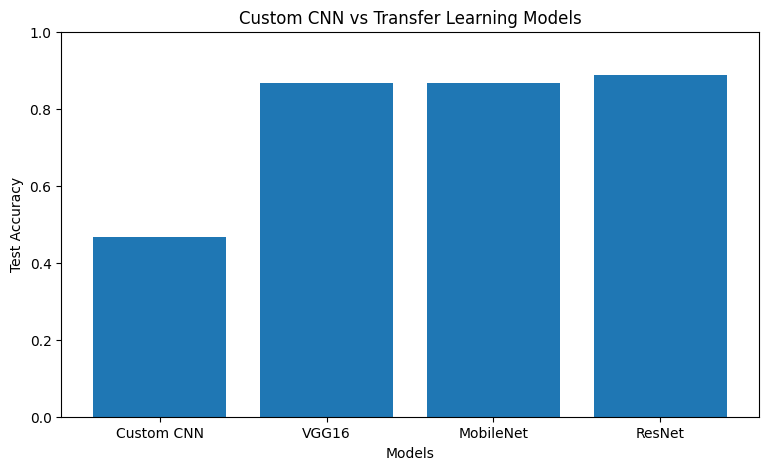

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

# Q3

def build_transfer_model(model_name):

    input_layer = layers.Input(shape=(64, 64, 3))

    if model_name == "VGG16":
        base_model = tf.keras.applications.VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=(64, 64, 3)
        )
        preprocess = tf.keras.applications.vgg16.preprocess_input

    elif model_name == "MobileNet":
        base_model = tf.keras.applications.MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(64, 64, 3)
        )
        preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

    else:
        base_model = tf.keras.applications.ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(64, 64, 3)
        )
        preprocess = tf.keras.applications.resnet50.preprocess_input

    base_model.trainable = False

    x = layers.Lambda(preprocess)(input_layer)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output_layer = layers.Dense(3, activation="softmax")(x)

    model = models.Model(input_layer, output_layer)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

results = {
    "Custom CNN": custom_metrics
}

for name in ["VGG16", "MobileNet", "ResNet"]:

    print("\nTraining:", name)

    model = build_transfer_model(name)

    callback = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=32,
        callbacks=[callback]
    )

    predictions = np.argmax(
        model.predict(X_test), axis=1
    )

    results[name] = calculate_metrics(
        y_test, predictions, name
    )

print("\nFINAL MODEL COMPARISON")

for name, metrics in results.items():
    print("\n", name)
    print("Accuracy:", round(metrics[0], 4))
    print("Precision:", round(metrics[1], 4))
    print("Recall:", round(metrics[2], 4))
    print("F1 Score:", round(metrics[3], 4))

names = list(results.keys())
accuracies = [results[name][0] for name in names]

plt.figure(figsize=(9, 5))
plt.bar(names, accuracies)
plt.xlabel("Models")
plt.ylabel("Test Accuracy")
plt.title("Custom CNN vs Transfer Learning Models")
plt.ylim(0, 1)
plt.show()
